In [1]:
import pandas as pd

df = pd.read_csv("../reports/validation_predictions.csv")

print(df.shape)
df[["Churn", "ChurnProbability"]].head()

(118839, 21)


,Churn,ChurnProbability
0,1,0.585332
1,0,0.001864
2,0,0.043234
3,1,0.628598
4,0,0.098739


In [2]:
# 按预测流失分数划分五个风险等级
risk_labels = ["Very Low", "Low", "Medium", "High", "Very High"]

df["RiskLevel"] = pd.qcut(
    df["ChurnProbability"].rank(method="first"),
    q=5,
    labels=risk_labels
)

# 统计各风险等级的客户数量和实际流失率
risk_summary = (
    df.groupby("RiskLevel", observed=True)
    .agg(
        Customers=("Churn", "size"),
        ChurnRate=("Churn", "mean"),
        AvgRiskScore=("ChurnProbability", "mean")
    )
)

risk_summary["ChurnRate"] *= 100

risk_summary.round(2)

,Customers,ChurnRate,AvgRiskScore
RiskLevel,,,
Very Low,23768,0.21,0.00
Low,23768,1.24,0.01
Medium,23767,7.51,0.08
High,23768,32.30,0.32
Very High,23768,71.35,0.71


In [3]:
# 不同风险等级的合同类型分布
contract_distribution = pd.crosstab(
    df["RiskLevel"],
    df["Contract"],
    normalize="index"
) * 100

contract_distribution.round(2)

Contract,Month-to-month,One year,Two year
RiskLevel,,,
Very Low,0.00,0.16,99.84
Low,7.41,51.27,41.31
Medium,53.85,29.70,16.45
High,90.67,9.14,0.19
Very High,99.89,0.11,0.00


In [4]:
# 筛选月付合同客户
monthly_df = df[df["Contract"] == "Month-to-month"].copy()

# 在月付客户内部重新划分五个风险等级
monthly_df["RiskGroup"] = pd.qcut(
    monthly_df["ChurnProbability"].rank(method="first"),
    q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"]
)

# 计算各风险等级的实际流失率
monthly_summary = (
    monthly_df.groupby("RiskGroup", observed=True)
    .agg(
        Customers=("Churn", "size"),
        ChurnRate=("Churn", "mean"),
        AvgRiskScore=("ChurnProbability", "mean")
    )
)

monthly_summary["ChurnRate"] *= 100

monthly_summary.round(2)

,Customers,ChurnRate,AvgRiskScore
RiskGroup,,,
Very Low,11971,5.90,0.06
Low,11970,21.58,0.21
Medium,11971,40.43,0.41
High,11970,59.57,0.60
Very High,11971,82.82,0.82


In [5]:
# 比较月付客户不同风险等级的连续变量特征
monthly_profile = (
    monthly_df.groupby("RiskGroup", observed=True)
    .agg(
        Customers=("Churn", "size"),
        AvgTenure=("tenure", "mean"),
        MedianTenure=("tenure", "median"),
        AvgMonthlyCharges=("MonthlyCharges", "mean"),
        AvgTotalCharges=("TotalCharges", "mean")
    )
)

monthly_profile.round(2)

,Customers,AvgTenure,MedianTenure,AvgMonthlyCharges,AvgTotalCharges
RiskGroup,,,,,
Very Low,11971,21.59,18.0,42.12,1109.15
Low,11970,25.73,22.0,67.91,2046.69
Medium,11971,22.63,18.0,77.87,2017.56
High,11970,15.58,12.0,81.73,1426.52
Very High,11971,6.94,5.0,86.85,667.39


In [6]:
# 月付客户不同风险等级的互联网服务类型分布
internet_distribution = pd.crosstab(
    monthly_df["RiskGroup"],
    monthly_df["InternetService"],
    normalize="index"
) * 100

internet_distribution.round(2)

InternetService,DSL,Fiber optic,No
RiskGroup,,,
Very Low,50.41,7.87,41.73
Low,44.84,51.83,3.33
Medium,21.42,78.25,0.33
High,11.48,88.50,0.02
Very High,1.72,98.28,0.00


In [7]:
# 已有 LightGBM Top-K 验证结果
budget_df = pd.DataFrame({
    "Budget": [0.1, 0.2, 0.3],
    "Contacted": [11883, 23767, 35651],
    "TrueChurn": [9859, 16958, 21804]
})

# 模拟参数
contact_cost = 10
retention_value = 200
success_rates = [0.1, 0.2, 0.3]

# 计算不同情景的期望净收益
for q in success_rates:
    budget_df[f"Profit_{int(q*100)}%"] = (
        budget_df["TrueChurn"] * q * retention_value
        - budget_df["Contacted"] * contact_cost
    )

budget_df

,Budget,Contacted,TrueChurn,Profit_10%,Profit_20%,Profit_30%
0,0.1,11883,9859,78350.0,275530.0,472710.0
1,0.2,23767,16958,101490.0,440650.0,779810.0
2,0.3,35651,21804,79570.0,515650.0,951730.0


In [8]:
# Logistic Regression 之前的 Top-K 结果
lr_true_churn = [9542, 16626, 21514]

# 基准情景参数
q = 0.2
V = 200
C = 10

# 计算两个模型的模拟收益
comparison = pd.DataFrame({
    "Budget": budget_df["Budget"],
    "Contacted": budget_df["Contacted"],
    "LR_TrueChurn": lr_true_churn,
    "LGB_TrueChurn": budget_df["TrueChurn"]
})

comparison["LR_Profit"] = (
    comparison["LR_TrueChurn"] * q * V
    - comparison["Contacted"] * C
)

comparison["LGB_Profit"] = (
    comparison["LGB_TrueChurn"] * q * V
    - comparison["Contacted"] * C
)

comparison["Extra_Profit"] = (
    comparison["LGB_Profit"] - comparison["LR_Profit"]
)

comparison

,Budget,Contacted,LR_TrueChurn,LGB_TrueChurn,LR_Profit,LGB_Profit,Extra_Profit
0,0.1,11883,9542,9859,262850.0,275530.0,12680.0
1,0.2,23767,16626,16958,427370.0,440650.0,13280.0
2,0.3,35651,21514,21804,504050.0,515650.0,11600.0


In [9]:
from sklearn.metrics import brier_score_loss, roc_auc_score

# 验证集真实标签和 LightGBM 预测概率
y_true = df["Churn"]
y_proba = df["ChurnProbability"]

# 计算 Brier Score
brier = brier_score_loss(y_true, y_proba)

# 再次检查 ROC-AUC
auc = roc_auc_score(y_true, y_proba)

print(f"LightGBM Brier Score: {brier:.4f}")
print(f"LightGBM ROC-AUC: {auc:.4f}")

LightGBM Brier Score: 0.0954
LightGBM ROC-AUC: 0.9160


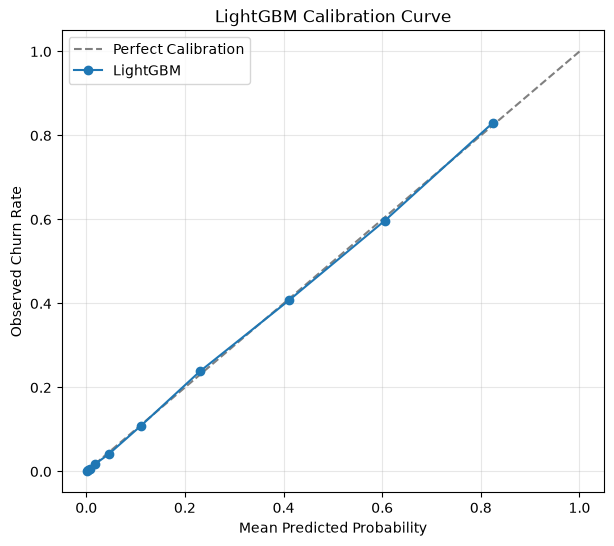

In [10]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# 将预测概率划分为 10 个分位数组
prob_true, prob_pred = calibration_curve(
    y_true,
    y_proba,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

# 理想校准线
plt.plot(
    [0, 1], [0, 1],
    "--", color="gray",
    label="Perfect Calibration"
)

# LightGBM 校准曲线
plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="LightGBM"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Churn Rate")
plt.title("LightGBM Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()